<a href="https://colab.research.google.com/github/fmckenzie05/brunel-supply-chain/blob/master/brunel_supply_chain_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [27]:
!nvidia-smi

Fri Nov 13 00:36:29 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P0             26W /   70W |     265MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [28]:
%load_ext cudf.pandas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from google.colab import drive
drive.mount('/content/drive')
sns.set_theme(style='whitegrid', context='notebook')
BLUE, GREY = '#3B6FD4', '#B8BCC6'

The cudf.pandas extension is already loaded. To reload it, use:
  %reload_ext cudf.pandas
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [29]:
BASE = '/content/drive/MyDrive/data_analysis_brunel/'
files = ['order_costs', 'by_carrier', 'by_plant', 'by_service_level', 'summary', 'top_customers']
dfs = {f: pd.read_csv(os.path.join(BASE, f + '.csv')) for f in files}
for n, d in dfs.items():
    print(f"{n}: {d.shape[0]:,} x {d.shape[1]}")

orders = dfs['order_costs'].copy()
for c in ['is_on_time', 'is_shipped_early', 'is_crf']:
    orders[c] = orders[c].astype(str).str.lower().map(
        {'t': True, 'true': True, '1': True, 'f': False, 'false': False, '0': False})
orders['wh_per_unit'] = orders['warehouse_cost'] / orders['unit_quantity']


order_costs: 9,212 x 21
by_carrier: 4 x 12
by_plant: 19 x 9
by_service_level: 3 x 6
summary: 1 x 15
top_customers: 46 x 6


**Data Overview**

In [30]:
print(orders.shape)
orders.info()
print("\nNulls: \n", orders.isna().sum()[orders.isna().sum() > 0])
print("Duplicate order_ids:", orders['order_id'].duplicated().sum())

(9212, 22)
<class 'cudf.core.dataframe.DataFrame'>
RangeIndex: 9212 entries, 0 to 9211
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   order_id          9212 non-null   float64
 1   order_date        9212 non-null   object
 2   plant_code        9212 non-null   object
 3   origin_port       9212 non-null   object
 4   dest_port         9212 non-null   object
 5   carrier           9212 non-null   object
 6   service_level     9212 non-null   object
 7   customer          9212 non-null   object
 8   product_id        9212 non-null   int64
 9   unit_quantity     9212 non-null   int64
 10  weight            9212 non-null   float64
 11  transit_days      9212 non-null   int64
 12  ship_ahead_days   9212 non-null   int64
 13  ship_late_days    9212 non-null   int64
 14  is_on_time        9212 non-null   bool
 15  is_shipped_early  9212 non-null   bool
 16  is_crf            9212 non-null   bool
 17  is_qty_outli

**Descriptive stats: Numeric Columns**

In [31]:
num = ['unit_quantity', 'weight', 'freight_cost', 'warehouse_cost', 'wh_per_unit', 'transit_days', 'ship_late_days']
desc = orders[num].describe(percentiles=[.25, .5, .75, .95]).T
desc['skew'] = orders[num].skew()
desc.round(2)

,count,mean,std,min,25%,50%,75%,95%,max,skew
unit_quantity,9212.0,3203.68,15968.14,235.00,330.00,477.00,1276.00,11356.45,561847.00,18.14
weight,9212.0,19.88,66.58,0.01,1.41,4.45,13.33,73.94,2338.41,11.13
freight_cost,7848.0,8.87,352.51,0.00,1.50,1.50,1.50,3.67,28711.93,72.13
warehouse_cost,9212.0,1697.00,8263.88,112.73,173.36,256.68,670.30,6346.54,290756.95,18.11
wh_per_unit,9212.0,0.55,0.19,0.43,0.52,0.52,0.52,0.77,1.92,6.56
transit_days,9212.0,1.72,0.63,0.00,1.00,2.00,2.00,2.00,4.00,-0.39
ship_late_days,9212.0,0.04,0.32,0.00,0.00,0.00,0.00,0.00,6.00,9.86


**Descriptive Stats: Categories**

In [32]:
for c in ['plant_code', 'carrier', 'service_level', 'mode']:
  vc = orders[c].value_counts()
  display(pd.DataFrame({'orders': vc, '%': (vc / len(orders) * 100).round(1)}))

,orders,%
plant_code,,
PLANT03,8538,92.7
PLANT12,300,3.3
PLANT16,173,1.9
PLANT08,102,1.1
PLANT13,86,0.9
PLANT09,12,0.1
PLANT04,1,0.0


,orders,%
carrier,,
V444_0,6262,68.0
V444_1,2097,22.8
V44_3,853,9.3


,orders,%
service_level,,
DTP,6216,67.5
DTD,2143,23.3
CRF,853,9.3


,orders,%
mode,,
AIR,6961,75.6
GROUND,34,0.4


**Distributions: What a typical order looks like**

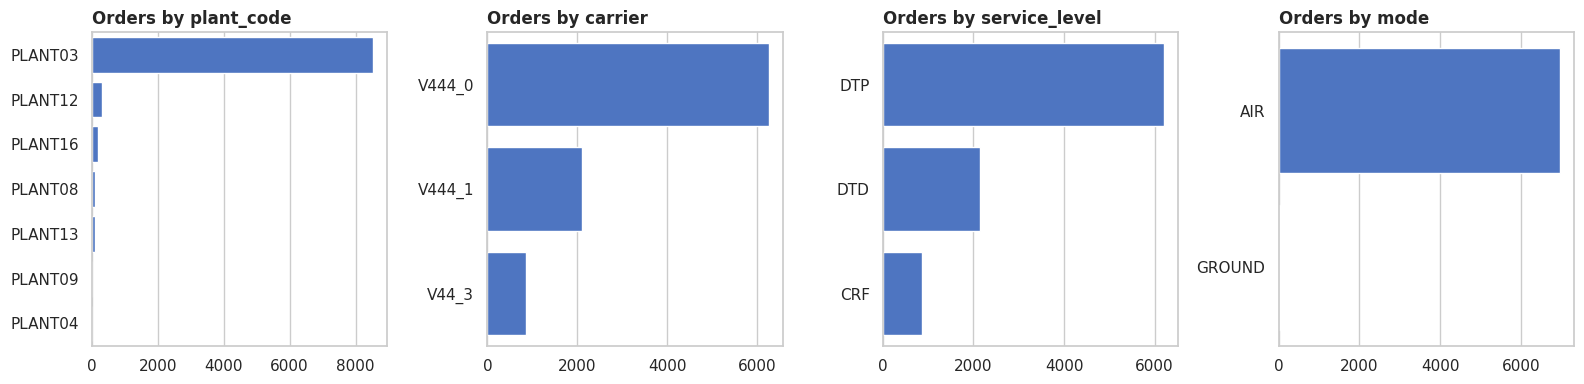

In [33]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, ['plant_code', 'carrier', 'service_level', 'mode']):
    sns.countplot(data=orders, y=c, order=orders[c].value_counts().index, color=BLUE, ax=ax)
    ax.set_title(f'Orders by {c}', loc='left', fontweight='bold'); ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout(); plt.show()

**Warehouse Story: Where cost concentrates**

In [34]:
wh = (orders.groupby('plant_code')
      .agg(orders=('order_id', 'count'), units=('unit_quantity', 'sum'),
           wh_cost=('warehouse_cost', 'sum'),
           median_per_unit=('wh_per_unit', 'median')))
wh['avg_per_unit'] = wh['wh_cost'] / wh['units']
wh['share_cost_%'] = wh['wh_cost'] / wh['wh_cost'].sum() * 100
wh['share_units_%'] = wh['units'] / wh['units'].sum() * 100
wh = wh.sort_values('wh_cost', ascending=False)
wh.round(3)

,orders,units,wh_cost,median_per_unit,avg_per_unit,share_cost_%,share_units_%
plant_code,,,,,,,
PLANT03,8538,28610640,14806065.72,0.518,0.518,94.712,96.945
PLANT16,173,245133,470608.31,1.920,1.920,3.010,0.831
PLANT08,102,277008,144835.59,0.523,0.523,0.926,0.939
PLANT09,12,223830,104096.85,0.465,0.465,0.666,0.758
PLANT12,300,112000,86590.76,0.773,0.773,0.554,0.380
PLANT13,86,43379,20375.44,0.470,0.470,0.130,0.147
PLANT04,1,348,149.12,0.429,0.429,0.001,0.001


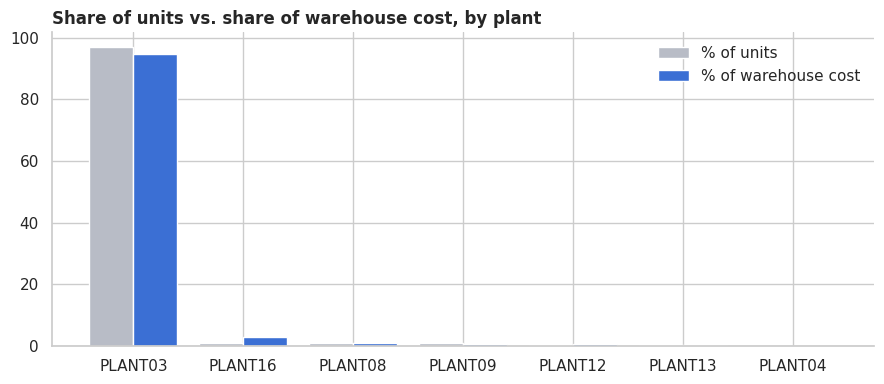

In [35]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(wh))
ax.bar(x - 0.2, wh['share_units_%'], 0.4, color=GREY, label='% of units')
ax.bar(x + 0.2, wh['share_cost_%'], 0.4, color=BLUE, label='% of warehouse cost')
ax.set_xticks(x, wh.index)
ax.set_title('Share of units vs. share of warehouse cost, by plant', loc='left', fontweight='bold')
ax.legend(frameon=False); sns.despine()
plt.tight_layout(); plt.show()

**Cost-per-unit spread by plant**

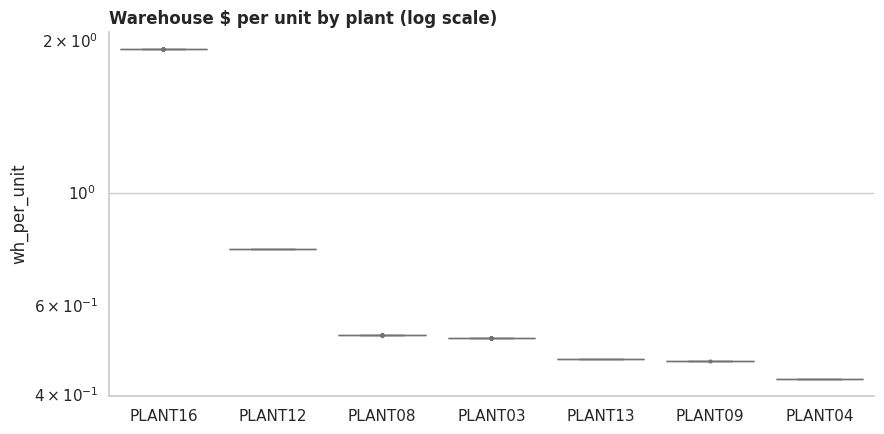

In [36]:
order_idx = wh.sort_values('avg_per_unit', ascending=False).index
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=orders, x='plant_code', y='wh_per_unit', order=order_idx,
            color=GREY, fliersize=2, ax=ax)
ax.set_yscale('log')
ax.set_title('Warehouse $ per unit by plant (log scale)', loc='left', fontweight='bold')
ax.set_xlabel(''); sns.despine()
plt.tight_layout(); plt.show()

**Relationship between the numeric columns**

                unit_quantity  weight  freight_cost  warehouse_cost  \
unit_quantity            1.00    0.69          0.18            0.98   
weight                   0.69    1.00          0.34            0.71   
freight_cost             0.18    0.34          1.00            0.17   
warehouse_cost           0.98    0.71          0.17            1.00   
transit_days            -0.01   -0.10          0.52           -0.02   

                transit_days  
unit_quantity          -0.01  
weight                 -0.10  
freight_cost            0.52  
warehouse_cost         -0.02  
transit_days            1.00  


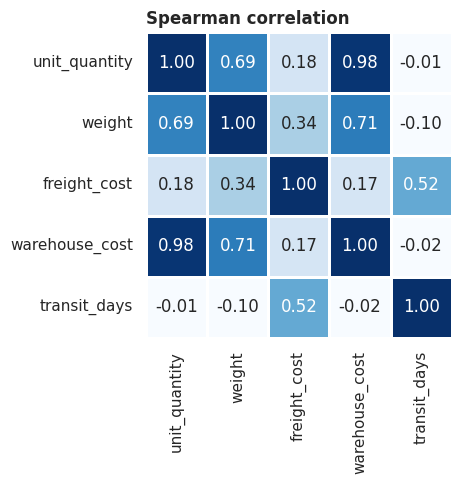

In [37]:
cols = ['unit_quantity', 'weight', 'freight_cost', 'warehouse_cost', 'transit_days']
num_df = orders[cols].apply(pd.to_numeric, errors='coerce')

corr = num_df.corr(method='spearman')
print(corr.round(2))          # check the table before plotting

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(np.asarray(corr.values, dtype=float), annot=True, fmt='.2f', cmap='Blues',
            vmin=0, vmax=1, square=True, linewidths=2, linecolor='white', cbar=False,
            xticklabels=cols, yticklabels=cols, ax=ax)
ax.set_title('Spearman correlation', loc='left', fontweight='bold')
plt.tight_layout(); plt.show()

**Plant x Carrier: where the volume flows**

carrier     V444_0  V444_1  V44_3
plant_code                       
PLANT03      22.99    2.05   3.58
PLANT04       0.00    0.00   0.00
PLANT08       0.28    0.00   0.00
PLANT09       0.22    0.00   0.00
PLANT12       0.07    0.04   0.00
PLANT13       0.04    0.00   0.00
PLANT16       0.01    0.00   0.23


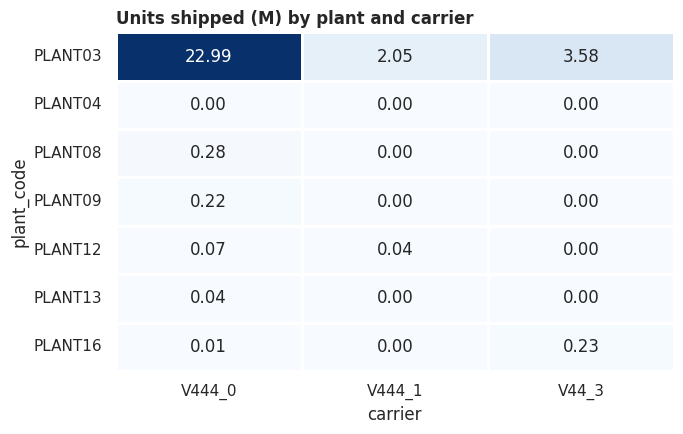

In [38]:
tmp = orders[['plant_code', 'carrier']].copy()
tmp['units_m'] = pd.to_numeric(orders['unit_quantity'], errors='coerce') / 1e6

pv = tmp.pivot_table(index='plant_code', columns='carrier', values='units_m',
                     aggfunc='sum', fill_value=0)
print(pv.round(2))   # check the table before plotting

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.heatmap(np.asarray(pv.values, dtype=float), annot=True, fmt='.2f', cmap='Blues',
            linewidths=2, linecolor='white', cbar=False,
            xticklabels=list(pv.columns), yticklabels=list(pv.index), ax=ax)
ax.set_title('Units shipped (M) by plant and carrier', loc='left', fontweight='bold')
ax.set_xlabel('carrier'); ax.set_ylabel('plant_code')
plt.tight_layout(); plt.show()

**Delivery by service level**

In [39]:
d = orders[['service_level', 'order_id']].copy()
d['on_time'] = orders['is_on_time'].astype(float)
d['early'] = orders['is_shipped_early'].astype(float)
d['transit'] = pd.to_numeric(orders['transit_days'], errors='coerce')

svc = d.groupby('service_level').agg(
    orders=('order_id', 'count'),
    on_time_pct=('on_time', 'mean'),
    early_pct=('early', 'mean'),
    avg_transit=('transit', 'mean'))
svc[['on_time_pct', 'early_pct']] *= 100
svc.round(1)

,orders,on_time_pct,early_pct,avg_transit
service_level,,,,
CRF,853,100.0,67.3,1.3
DTD,2143,99.6,53.3,1.1
DTP,6216,97.1,49.4,2.0
